In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/yeonjiji/separation-data/test.jsonl
/kaggle/input/datasets/yeonjiji/separation-data/validate.jsonl
/kaggle/input/datasets/yeonjiji/separation-data/train.jsonl
/kaggle/input/notebooks/yeonjiji/01-fine-tune-separationllm/__results__.html
/kaggle/input/notebooks/yeonjiji/01-fine-tune-separationllm/__huggingface_repos__.json
/kaggle/input/notebooks/yeonjiji/01-fine-tune-separationllm/__notebook__.ipynb
/kaggle/input/notebooks/yeonjiji/01-fine-tune-separationllm/__output__.json
/kaggle/input/notebooks/yeonjiji/01-fine-tune-separationllm/custom.css
/kaggle/input/notebooks/yeonjiji/01-fine-tune-separationllm/separationllm-qwen3-1.7b-lora/README.md
/kaggle/input/notebooks/yeonjiji/01-fine-tune-separationllm/separationllm-qwen3-1.7b-lora/checkpoint-603/adapter_model.safetensors
/kaggle/input/notebooks/yeonjiji/01-fine-tune-separationllm/separationllm-qwen3-1.7b-lora/checkpoint-603/trainer_state.json
/kaggle/input/notebooks/yeonjiji/01-fine-tune-separationllm/separationllm

In [2]:
# Install compatible packages for PEFT / LoRA loading

%pip uninstall -y torchao

%pip install -q \
    transformers==5.16.1 \
    peft==0.20.0 \
    datasets \
    accelerate \
    scikit-learn \
    tqdm

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [3]:
# Verify that torchao is not installed

import importlib.util

print(
    "torchao installed:",
    importlib.util.find_spec("torchao") is not None
)

torchao installed: False


In [4]:
# final adaptor
ADAPTER_PATH = "/kaggle/input/notebooks/yeonjiji/01-fine-tune-separationllm/separationllm-qwen3-1.7b-lora-final"
ACT_PATH = "/kaggle/input/notebooks/yeonjiji/02-2-layer-activation-analysis/acts_for_sae.npz"

In [5]:
import numpy as np
import random
import torch

SEED = 2024
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

In [6]:
data = np.load(ACT_PATH)

# layers 15~23 are saved.
# find the position of layer 19
LAYER = 19
saved_layers = data["layers"]
li = int(np.where(saved_layers == LAYER)[0][0])

# SAE training set = train + val / held-out set = test
X_train = np.concatenate([data["train"][:, li], data["val"][:, li]]).astype(np.float32)
train_y = np.concatenate([data["train_y"], data["val_y"]])

X_test = data["test"][:, li].astype(np.float32)
test_y = data["test_y"]

print("layer index:", li)
print("train:", X_train.shape)
print("test:", X_test.shape)

layer index: 4
train: (2002, 2048)
test: (501, 2048)


In [7]:
# normalization stats from the SAE training set only
from torch.utils.data import DataLoader, TensorDataset

mean = X_train.mean(axis=0, keepdims=True)
std = X_train.std(axis=0, keepdims=True) + 1e-6

X_train_norm = (X_train - mean) / std
X_test_norm = (X_test - mean) / std

train_tensor = torch.tensor(X_train_norm, dtype=torch.float32)
test_tensor = torch.tensor(X_test_norm, dtype=torch.float32)

g = torch.Generator().manual_seed(SEED)    # fixed shuffle order
train_loader = DataLoader(
    TensorDataset(train_tensor),
    batch_size=64,
    shuffle=True,
    generator=g
)

print(train_tensor.shape, len(train_loader))

torch.Size([2002, 2048]) 32


### Top-K Sparse Autoencoder

In [8]:
import torch.nn as nn

INPUT_DIM = 2048
SAE_DIM = 2048
K = 64

class TopKSparseAutoencoder(nn.Module):
    def __init__(self, input_dim, hidden_dim, k):
        super().__init__()

        self.encoder = nn.Linear(input_dim, hidden_dim)
        self.decoder = nn.Linear(hidden_dim, input_dim)
        self.k = k

    def forward(self, x):
        pre_features = torch.relu(self.encoder(x))    # <0 -> 0

        values, indices = torch.topk(                 # find indices of the top 64 features
            pre_features,
            self.k,
            dim=-1
        )

        features = torch.zeros_like(pre_features)     # make 2048 vectors to 0

        features.scatter_(                            # and put 64 features
            1,
            indices,
            values
        )

        recon = self.decoder(features)

        return recon, features

In [9]:
# Loss
import torch.nn.functional as F

def sae_loss(recon, x):
    reconstruction_loss = F.mse_loss(
        recon,
        x
    )

    return reconstruction_loss

In [10]:
# fix the seed before creating the SAE
torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"

sae = TopKSparseAutoencoder(INPUT_DIM, SAE_DIM, K).to(device)
optimizer = torch.optim.Adam(sae.parameters(), lr=1e-3)

In [11]:
EPOCHS = 50
test_tensor_dev = test_tensor.to(device)

for epoch in range(EPOCHS):
    sae.train()
    total_loss = 0

    for (batch,) in train_loader:        # 64 samples per batch
        batch = batch.to(device)        
        optimizer.zero_grad()            # clear gradients from the previous step
        recon, features = sae(batch)     # encode -> keep top-64 -> decode
        loss = sae_loss(recon, batch)    # reconstruction error (MSE) vs. original vector
        loss.backward()                  # compute gradients
        optimizer.step()                 # update encoder/decoder weights
        total_loss += loss.item()


    if (epoch + 1) % 5 == 0:             # report every 5 epochs
        sae.eval()
        with torch.no_grad():
            test_recon, _ = sae(test_tensor_dev)    # reconstruct held-out test vectors
            test_loss = sae_loss(test_recon, test_tensor_dev).item()
        print(f"Epoch {epoch+1:02d} | train {total_loss/len(train_loader):.4f} | test {test_loss:.4f}")

Epoch 05 | train 0.0428 | test 0.0415
Epoch 10 | train 0.0266 | test 0.0295
Epoch 15 | train 0.0197 | test 0.0221
Epoch 20 | train 0.0164 | test 0.0204
Epoch 25 | train 0.0142 | test 0.0182
Epoch 30 | train 0.0138 | test 0.0172
Epoch 35 | train 0.0117 | test 0.0149
Epoch 40 | train 0.0138 | test 0.0178
Epoch 45 | train 0.0117 | test 0.0165
Epoch 50 | train 0.0103 | test 0.0140


**Conversion val/test activation into SAE feature**

In [12]:
# calculate feature + check dead feature
sae.eval()
with torch.no_grad():
    _, fit_features = sae(train_tensor.to(device))    # train + val (1602 + 400 -> 2002)
    _, test_features = sae(test_tensor_dev)    # test (501)

fit_features = fit_features.cpu().numpy()
test_features = test_features.cpu().numpy()

# split out the val part (used for feature selection)
n_tr = len(data["train"])    # 1602
val_features = fit_features[n_tr:]    # (400, 2048)
val_y = train_y[n_tr:]

print(fit_features.shape, val_features.shape, test_features.shape)

(2002, 2048) (400, 2048) (501, 2048)


In [13]:
freq_fit = (fit_features > 0).mean(axis=0)    # how often each feature fires (train+val)
freq_test = (test_features > 0).mean(axis=0)

print("dead (train+val):", np.sum(freq_fit == 0), "/ 2048")
print("dead (test):", np.sum(freq_test == 0), "/ 2048")
print("always-on (>95%):", np.sum(freq_fit > 0.95))

activation_frequency = (val_features > 0).mean(axis=0)

dead (train+val): 1037 / 2048
dead (test): 1148 / 2048
always-on (>95%): 0


* **Dead feature**: a feature that is never among the top-64 for any sample 
* (activation = 0 for all samples) when the trained SAE is applied to the data.

> #### Which feature is related to D-class most?

In [14]:
D_MAP = {"VL": 0, "L": 1, "U": 2, "M": 3, "H": 4}

val_d = np.array([D_MAP[str(x)] for x in val_y])
test_d = np.array([D_MAP[str(x)] for x in test_y])

In [15]:
# feature correlation
feature_corr = []

for i in range(val_features.shape[1]):
    x = val_features[:, i]

    if np.std(x) < 1e-8:
        feature_corr.append(0.0)
        continue

    corr = np.corrcoef(x, val_d)[0, 1]
    feature_corr.append(corr)

feature_corr = np.nan_to_num(np.array(feature_corr))

In [16]:
# high-D and low-D features
TOP_N = 10
top_positive = np.argsort(feature_corr)[-TOP_N:][::-1]
top_negative = np.argsort(feature_corr)[:TOP_N]

print("High-D features (val)")
for idx in top_positive:
    print(f"Feature {idx:4d} | corr = {feature_corr[idx]:+.3f} | freq = {activation_frequency[idx]:.3f}")

print("\nLow-D features (val)")
for idx in top_negative:
    print(f"Feature {idx:4d} | corr = {feature_corr[idx]:+.3f} | freq = {activation_frequency[idx]:.3f}")

High-D features (val)
Feature 1208 | corr = +0.568 | freq = 0.415
Feature  380 | corr = +0.522 | freq = 0.220
Feature 1205 | corr = +0.521 | freq = 0.282
Feature 1256 | corr = +0.499 | freq = 0.270
Feature 1808 | corr = +0.493 | freq = 0.310
Feature  991 | corr = +0.490 | freq = 0.163
Feature  565 | corr = +0.454 | freq = 0.225
Feature 1490 | corr = +0.450 | freq = 0.263
Feature 1423 | corr = +0.441 | freq = 0.152
Feature  355 | corr = +0.439 | freq = 0.158

Low-D features (val)
Feature  827 | corr = -0.538 | freq = 0.328
Feature 1615 | corr = -0.522 | freq = 0.265
Feature  245 | corr = -0.508 | freq = 0.463
Feature 1014 | corr = -0.508 | freq = 0.315
Feature  271 | corr = -0.481 | freq = 0.245
Feature 1497 | corr = -0.460 | freq = 0.228
Feature 1627 | corr = -0.453 | freq = 0.310
Feature 1239 | corr = -0.451 | freq = 0.245
Feature 1999 | corr = -0.443 | freq = 0.260
Feature  402 | corr = -0.442 | freq = 0.352


In [17]:
# Correlation of given features on a given set
def corr_on(features, d, idx):
    out = []
    for i in idx:
        x = features[:, i]
        out.append(0.0 if np.std(x) < 1e-8 else np.corrcoef(x, d)[0, 1])
    return np.array(out)

test_corr_pos = corr_on(test_features, test_d, top_positive)
test_corr_neg = corr_on(test_features, test_d, top_negative)
test_freq = (test_features > 0).mean(axis=0)

print("High-D features: val vs test")
for i, c in zip(top_positive, test_corr_pos):
    print(f"Feature {i:4d} | val = {feature_corr[i]:+.3f} | test = {c:+.3f} | test freq = {test_freq[i]:.3f}")

print("\nLow-D features: val vs test")
for i, c in zip(top_negative, test_corr_neg):
    print(f"Feature {i:4d} | val = {feature_corr[i]:+.3f} | test = {c:+.3f} | test freq = {test_freq[i]:.3f}")

# Reference: typical |corr| of all alive features on test
alive = np.where(test_freq > 0)[0]
all_test_corr = corr_on(test_features, test_d, alive)
print(f"\nAll alive features on test: median |corr| = {np.median(np.abs(all_test_corr)):.3f}")

High-D features: val vs test
Feature 1208 | val = +0.568 | test = +0.576 | test freq = 0.423
Feature  380 | val = +0.522 | test = +0.543 | test freq = 0.222
Feature 1205 | val = +0.521 | test = +0.524 | test freq = 0.277
Feature 1256 | val = +0.499 | test = +0.504 | test freq = 0.275
Feature 1808 | val = +0.493 | test = +0.457 | test freq = 0.287
Feature  991 | val = +0.490 | test = +0.489 | test freq = 0.178
Feature  565 | val = +0.454 | test = +0.432 | test freq = 0.198
Feature 1490 | val = +0.450 | test = +0.421 | test freq = 0.275
Feature 1423 | val = +0.441 | test = +0.437 | test freq = 0.166
Feature  355 | val = +0.439 | test = +0.482 | test freq = 0.174

Low-D features: val vs test
Feature  827 | val = -0.538 | test = -0.541 | test freq = 0.345
Feature 1615 | val = -0.522 | test = -0.536 | test freq = 0.265
Feature  245 | val = -0.508 | test = -0.527 | test freq = 0.495
Feature 1014 | val = -0.508 | test = -0.567 | test freq = 0.339
Feature  271 | val = -0.481 | test = -0.438 | 

In [18]:
from datasets import load_dataset
from collections import Counter
import re

# find which metal each sample uses from the original test data
DATA_DIR = "/kaggle/input/datasets/yeonjiji/separation-data"
test_dataset = load_dataset("json", data_files=f"{DATA_DIR}/test.jsonl", split="train")

# Sanity check: row i of test_features must be the same sample as test_dataset[i]
# If the order were shuffled anywhere, this assert fails and we stop here.
labels_from_text = np.array([D_MAP[x["messages"][-1]["content"].strip()] for x in test_dataset])
assert (labels_from_text == test_d).all(), "Order mismatch between dataset and activations"

def extract_metal(example):
    text = example["messages"][1]["content"]
    m = re.search(r'\b(Am|Eu|U|Th|Pu|Np|Pa|Cm)\s*\([IVX]+\)', text)
    return m.group(1) if m else None

test_metal = np.array([extract_metal(x) for x in test_dataset])
print(Counter(test_metal))

Generating train split: 0 examples [00:00, ? examples/s]

Counter({np.str_('U'): 220, np.str_('Pu'): 163, np.str_('Np'): 60, np.str_('Th'): 38, np.str_('Am'): 14, np.str_('Pa'): 6})


In [19]:
# skip metals with too few samples to avoid unstable correlations
MIN_N = 30
metals = [m for m, n in Counter(test_metal).items() if m is not None and n >= MIN_N]

def within_metal_table(idx_list, title):
    print(title)
    print("Feature |  all  | " + " | ".join(f"{m:>5}" for m in metals))

    for i in idx_list:
        # First column: correlation using every test sample
        row = [corr_on(test_features, test_d, [i])[0]]

        for m in metals:
            mask = test_metal == m    # True only for samples with this metal

            # if every sample of this metal has the same D, corr can't be computed -> mark as nan
            if np.std(test_d[mask]) < 1e-8:    
                row.append(np.nan)
            else:
                row.append(corr_on(test_features[mask], test_d[mask], [i])[0])

        print(f"{i:7d} | " + " | ".join(f"{c:+.2f}" for c in row))

# Sample count per metal, for reference when reading the table
print("n per metal:", {m: int((test_metal == m).sum()) for m in metals}, "\n")

within_metal_table(top_positive, "High-D features (test)")
print()
within_metal_table(top_negative, "Low-D features (test)")

n per metal: {np.str_('Pu'): 163, np.str_('U'): 220, np.str_('Th'): 38, np.str_('Np'): 60} 

High-D features (test)
Feature |  all  |    Pu |     U |    Th |    Np
   1208 | +0.58 | +0.70 | +0.57 | +0.32 | +0.80
    380 | +0.54 | +0.55 | +0.56 | +0.00 | +0.76
   1205 | +0.52 | +0.51 | +0.67 | +0.00 | +0.57
   1256 | +0.50 | +0.37 | +0.60 | +0.00 | +0.52
   1808 | +0.46 | +0.14 | +0.68 | +0.00 | +0.00
    991 | +0.49 | +0.54 | +0.51 | +0.00 | +0.64
    565 | +0.43 | +0.45 | +0.50 | +0.00 | +0.00
   1490 | +0.42 | +0.42 | +0.52 | +0.00 | +0.27
   1423 | +0.44 | +0.44 | +0.56 | +0.00 | +0.03
    355 | +0.48 | +0.55 | +0.44 | +0.24 | +0.70

Low-D features (test)
Feature |  all  |    Pu |     U |    Th |    Np
    827 | -0.54 | -0.58 | -0.22 | +0.18 | -0.54
   1615 | -0.54 | -0.54 | -0.36 | -0.19 | -0.46
    245 | -0.53 | -0.53 | -0.35 | -0.42 | -0.59
   1014 | -0.57 | -0.60 | -0.17 | -0.53 | -0.57
    271 | -0.44 | -0.40 | -0.30 | +0.43 | -0.47
   1497 | -0.51 | -0.51 | -0.33 | -0.52 | -0.

> #### Counterfactual

In [20]:
def extract_hno3(example):
    text = example["messages"][1]["content"]
    m = re.search(r'([\d.]+)\s*M\s*HNO3', text)
    return float(m.group(1)) if m else None

test_hno3 = np.array([extract_hno3(x) for x in test_dataset], dtype=object)
cf_idx = np.array([i for i, v in enumerate(test_hno3) if v is not None])
print("Samples with explicit HNO3:", len(cf_idx), "/", len(test_dataset))
print("Metals among them:", Counter(test_metal[cf_idx]))

Samples with explicit HNO3: 458 / 501
Metals among them: Counter({np.str_('U'): 194, np.str_('Pu'): 155, np.str_('Np'): 57, np.str_('Th'): 32, np.str_('Am'): 14, np.str_('Pa'): 6})


In [21]:
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import PeftModel
from tqdm.auto import tqdm

MODEL_NAME = "Qwen/Qwen3-1.7B"
DEVICE = "cuda"

# so layer-19 vectors here match the vectors the SAE was trained on
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
base_model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.float16, device_map="cuda")
ft_model = PeftModel.from_pretrained(base_model, ADAPTER_PATH)
ft_model.eval()


# Pull a concentration value (e.g. HNO3 or nitrate) from the prompt text
def extract_conc(text, name):
    match = re.search(rf'([\d.]+)\s*M\s*{name}', text)
    return float(match.group(1)) if match else None

# Replace HNO3 with new_hno3. If total nitrate is also written,
# keep the extra nitrate (from added salt) constant and shift nitrate with HNO3.
def make_hno3_counterfactual(example, new_hno3):
    messages = example["messages"]
    user_text = messages[1]["content"]
    old_hno3 = extract_conc(user_text, "HNO3")
    old_nitrate = extract_conc(user_text, "nitrate")

    new_text = re.sub(r'([\d.]+)\s*M\s*HNO3', f'{new_hno3:g} M HNO3', user_text)
    if old_nitrate is not None and old_hno3 is not None:
        extra_nitrate = max(old_nitrate - old_hno3, 0)
        new_nitrate = new_hno3 + extra_nitrate
        new_text = re.sub(r'([\d.]+)\s*M\s*nitrate', f'{new_nitrate:g} M nitrate', new_text)

    # Drop the answer message; keep system + modified user message only
    return [messages[0], {"role": "user", "content": new_text}]


# Run the model on a prompt and return the last-token vector after layer 19.
# Prompt format must match 02's extract_activations exactly
# (generation prompt on, thinking off, no extra special tokens).
def get_layer19_activation(messages):
    prompt = tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True, enable_thinking=False
    )
    inputs = tokenizer(prompt, return_tensors="pt", add_special_tokens=False).to(DEVICE)
    with torch.no_grad():
        out = ft_model(**inputs, output_hidden_states=True, use_cache=False, return_dict=True)
    # hidden_states[19] = output of layers[18] = "layer 19" (same index as 02)
    return out.hidden_states[19][0, -1, :].float().cpu().numpy()


# Turn one layer-19 vector into SAE features.
# Must use the SAME mean/std as SAE training (cell 7), otherwise inputs are on a different scale.
def activation_to_sae_features(layer_activation):
    x = (layer_activation - mean.squeeze()) / std.squeeze()
    x = torch.tensor(x, dtype=torch.float32).unsqueeze(0).to(device)   # shape [1, 2048]
    sae.eval()
    with torch.no_grad():
        _, features = sae(x)
    return features[0].cpu().numpy()                                   # shape [2048]


# Sanity check: an unchanged test prompt should reproduce the stored test features.
# If this differs a lot, the prompt format or model loading doesn't match 02.
i0 = int(cf_idx[0])
orig_msgs = test_dataset[i0]["messages"][:-1]
f_now = activation_to_sae_features(get_layer19_activation(orig_msgs))
print("Max diff vs stored features:", np.abs(f_now - test_features[i0]).max())

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Max diff vs stored features: 2.3841858e-06


In [22]:
# For every selected test sample, build two versions of the same prompt
# (HNO3 = 1 M and 6 M; everything else identical), and get SAE features for each.
feat_1M_all = []
feat_6M_all = []

for idx in tqdm(cf_idx):
    example = test_dataset[int(idx)]

    msg_1M = make_hno3_counterfactual(example, 1)
    msg_6M = make_hno3_counterfactual(example, 6)

    # prompt -> layer19 last-token vector -> SAE features [2048]
    feat_1M_all.append(activation_to_sae_features(get_layer19_activation(msg_1M)))
    feat_6M_all.append(activation_to_sae_features(get_layer19_activation(msg_6M)))

feat_1M_all = np.array(feat_1M_all)    # [n_samples, 2048]
feat_6M_all = np.array(feat_6M_all)    # [n_samples, 2048]

delta_features = feat_6M_all - feat_1M_all
print(delta_features.shape)

  0%|          | 0/458 [00:00<?, ?it/s]

(458, 2048)


In [23]:
mean_delta = delta_features.mean(axis=0)

# use features that were active in at least one of the 1M / 6M runs
active = np.where((feat_1M_all > 0).any(axis=0) | (feat_6M_all > 0).any(axis=0))[0]
abs_ref = np.abs(mean_delta[active])

def report(idx_list, title, expected_sign):
    print(title)
    for i in idx_list:
        d = mean_delta[i]
        # Fraction of samples where the change goes in the expected direction
        # (high-D features should go up with HNO3, low-D features down)
        frac = (np.sign(delta_features[:, i]) == expected_sign).mean()
        pct = (abs_ref < abs(d)).mean() * 100
        print(f"Feature {i:4d} | mean Δ = {d:+.3f} | expected-direction = {frac:.2f} | |Δ| percentile = {pct:5.1f}")

print(f"Active features: {len(active)} | median |mean Δ| = {np.median(abs_ref):.3f}\n")
report(top_positive, "High-D features (expect Δ > 0)", +1)
print()
report(top_negative, "Low-D features (expect Δ < 0)", -1)

Active features: 905 | median |mean Δ| = 0.031

High-D features (expect Δ > 0)
Feature 1208 | mean Δ = +4.459 | expected-direction = 0.74 | |Δ| percentile =  99.9
Feature  380 | mean Δ = +1.083 | expected-direction = 0.40 | |Δ| percentile =  97.9
Feature 1205 | mean Δ = +2.255 | expected-direction = 0.45 | |Δ| percentile =  99.6
Feature 1256 | mean Δ = +0.555 | expected-direction = 0.49 | |Δ| percentile =  94.8
Feature 1808 | mean Δ = +2.091 | expected-direction = 0.41 | |Δ| percentile =  99.4
Feature  991 | mean Δ = +0.154 | expected-direction = 0.24 | |Δ| percentile =  79.8
Feature  565 | mean Δ = +0.377 | expected-direction = 0.35 | |Δ| percentile =  92.0
Feature 1490 | mean Δ = +2.275 | expected-direction = 0.54 | |Δ| percentile =  99.7
Feature 1423 | mean Δ = +0.250 | expected-direction = 0.28 | |Δ| percentile =  87.3
Feature  355 | mean Δ = +1.035 | expected-direction = 0.35 | |Δ| percentile =  97.6

Low-D features (expect Δ < 0)
Feature  827 | mean Δ = -1.810 | expected-directio

**Reading the 1 M → 6 M results**

- **mean Δ**: average change in the feature's activation when HNO₃ goes from 1 M to 6 M (6 M − 1 M), over all samples.
- **expected-direction**: fraction of samples where the feature moved the expected way. Higher HNO₃ raises D, so high-D features should go up (Δ > 0) and low-D features should go down (Δ < 0). Samples where the feature was off at both 1 M and 6 M (Δ = 0) count as "not expected", so this value is a lower bound.
- **|Δ| percentile**: how large this feature's |mean Δ| is compared with all features active in either condition. For example, 99 means the change is larger than for 99% of those features.

In [24]:
import os

SAE_PATH = "/kaggle/working/sae_layer19_topk64.pt"

# Save the trained SAE + the normalization stats it was trained with.
# Feature numbers only stay the same if we reuse this exact SAE.
torch.save({
    "state_dict": sae.state_dict(),
    "mean": mean,      # from cell 7
    "std": std,
    "seed": SEED,
}, SAE_PATH)
print("Saved:", SAE_PATH, os.path.getsize(SAE_PATH) // 1024, "KB")

Saved: /kaggle/working/sae_layer19_topk64.pt 32810 KB


In [25]:
# see at different HNO3 conc values
HNO3_GRID = [0.5, 1, 2, 3, 4, 6, 8]

sweep = np.zeros((len(cf_idx), len(HNO3_GRID), 2048), dtype=np.float32)

for s, idx in enumerate(tqdm(cf_idx)):
    example = test_dataset[int(idx)]
    for c, hno3 in enumerate(HNO3_GRID):
        msg = make_hno3_counterfactual(example, hno3)    # same prompt, change HNO3
        sweep[s, c] = activation_to_sae_features(get_layer19_activation(msg))

print(sweep.shape)    # (n_samples, 7, 2048)

  0%|          | 0/458 [00:00<?, ?it/s]

(458, 7, 2048)


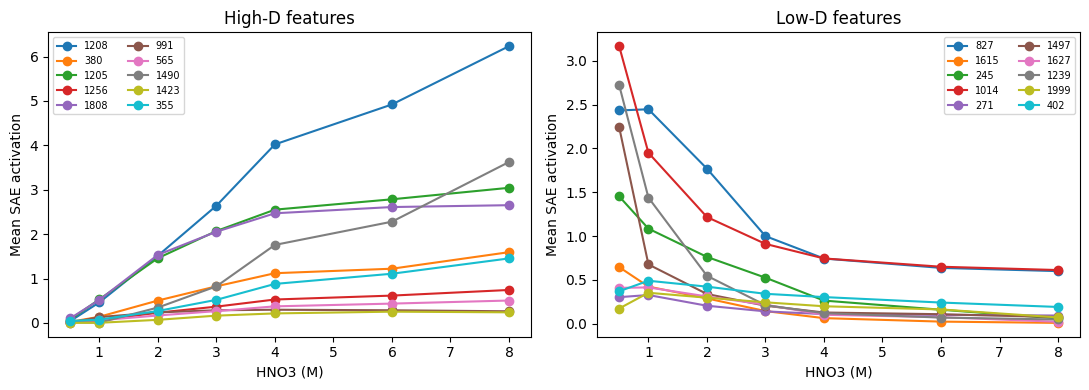

In [26]:
import matplotlib.pyplot as plt

# average over samples -> one curve per feature: shape [hno3 grid, 2048]
mean_sweep = sweep.mean(axis=0)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)

# Left: high-D features (expected to rise with HNO3)
for f in top_positive:
    axes[0].plot(HNO3_GRID, mean_sweep[:, f], marker="o", label=str(f))
axes[0].set_title("High-D features")

# Right: low-D features (expected to fall with HNO3)
for f in top_negative:
    axes[1].plot(HNO3_GRID, mean_sweep[:, f], marker="o", label=str(f))
axes[1].set_title("Low-D features")

for ax in axes:
    ax.set_xlabel("HNO3 (M)")
    ax.set_ylabel("Mean SAE activation")
    ax.legend(fontsize=7, ncol=2)

plt.tight_layout()
plt.show()

In [27]:
# find the representative features chosen from the results above
# (strong in 1M->6M test and consistent across metals)
REP_HIGH = 1208
REP_LOW = 245      # <0 for all four metals (827 -> +0.18 for Th)

def inspect_feature(feature_id, n_show=5, n_summary=50):
    values = test_features[:, feature_id]    # this feature's activation for every test sample
    order = np.argsort(values)[::-1]         # sample indices, strongest first
    
    # Summary over the top-50 strongest samples:
    # which D-classes and metals does this feature fire for?
    top = order[:n_summary]
    top = top[values[top] > 0]
    print(f"=== Feature {feature_id} | active in {(values > 0).mean():.1%} of test samples ===")
    print("D-class among top samples:", Counter(test_y[top]))
    print("Metal among top samples:  ", Counter(test_metal[top]))

    # read the actual prompts of the strongest few samples
    for i in order[:n_show]:
        print(f"\n[idx {i}] activation = {values[i]:.2f} | D = {test_y[i]} | metal = {test_metal[i]}")
        print(test_dataset[int(i)]["messages"][1]["content"])
    print("\n")

inspect_feature(REP_HIGH)
inspect_feature(REP_LOW)

=== Feature 1208 | active in 42.3% of test samples ===
D-class among top samples: Counter({np.str_('M'): 29, np.str_('H'): 19, np.str_('U'): 1, np.str_('L'): 1})
Metal among top samples:   Counter({np.str_('Pu'): 25, np.str_('U'): 17, np.str_('Np'): 8})

[idx 156] activation = 16.07 | D = H | metal = Pu
0.8 M of CCCCC(CC)CN(CC(CC)CCCC)C(=O)CCC in FS-13 is used to extract 0.002 mM Pu(IV) from an aqueous solution of 4 M HNO3 and 4 M nitrate at 20 C. The contact time is 60 min and the radiolytic dosage is <250 kGy.

[idx 204] activation = 15.78 | D = H | metal = Pu
2 M of CCCCC(CC)CN(CC(CC)CCCC)C(=O)CCC in TPH is used to extract trace Pu(IV) from an aqueous solution of 8 M HNO3 and 8 M nitrate at about 20 C. The contact time is 10 min and the radiolytic dosage is 0 kGy.

[idx 44] activation = 15.09 | D = H | metal = Pu
0.5 M of CCCCCCCCCC(=O)N(CC)CC in toluene is used to extract trace Pu(IV) from an aqueous solution of 6 M HNO3 and 6 M nitrate at 30 C. The contact time is unknown and the 

In [28]:
# Does the feature still track D when HNO3 is held fixed?
# If yes -> carries D info beyond acidity; if ~0 -> mostly an "acidity" feature
hno3_arr = np.array([v if v is not None else np.nan for v in test_hno3], dtype=float)

for f in [REP_HIGH, REP_LOW]:
    print(f"Feature {f}")
    for h, n in sorted(Counter(hno3_arr[~np.isnan(hno3_arr)]).items()):
        mask = hno3_arr == h
        if n < 20 or np.std(test_d[mask]) < 1e-8:   # too few samples or D doesn't vary
            continue
        c = corr_on(test_features[mask], test_d[mask], [f])[0]
        print(f"  HNO3 = {h:>4} M | n = {n:3d} | corr with D = {c:+.2f}")

Feature 1208
  HNO3 =  0.5 M | n =  20 | corr with D = +0.00
  HNO3 =  1.0 M | n =  38 | corr with D = +0.21
  HNO3 =  2.0 M | n =  67 | corr with D = +0.40
  HNO3 =  3.0 M | n = 113 | corr with D = +0.56
  HNO3 =  4.0 M | n =  75 | corr with D = +0.63
  HNO3 =  5.0 M | n =  33 | corr with D = +0.53
  HNO3 =  6.0 M | n =  45 | corr with D = +0.58
Feature 245
  HNO3 =  0.5 M | n =  20 | corr with D = -0.34
  HNO3 =  1.0 M | n =  38 | corr with D = -0.51
  HNO3 =  2.0 M | n =  67 | corr with D = -0.52
  HNO3 =  3.0 M | n = 113 | corr with D = -0.48
  HNO3 =  4.0 M | n =  75 | corr with D = -0.52
  HNO3 =  5.0 M | n =  33 | corr with D = -0.41
  HNO3 =  6.0 M | n =  45 | corr with D = -0.35


#### **Summary of Notebook 03**

A Top-K SAE (2048 features, k = 64) trained on layer-19 last-token activations reconstructs test activations well. Features were selected by their correlation with D-class on the validation set and confirmed on the held-out test set (|r| ≈ 0.4–0.56, vs. a median |r| of 0.08 across all active features).

- **Not metal identity:** the selected features keep their correlation with D within Pu, U and Np samples. High-D features are mostly inactive for Th, and low-D features are weaker for U.
- **Respond to HNO₃:** changing only HNO₃ from 1 M to 6 M moved all 20 selected features in the expected direction (*high-D up, low-D down*). Most of these changes rank in the top 10% of all features. A sweep from 0.5 to 8 M shows a graded, mostly monotonic response, with most of the change between 0.5 and 4 M.
- **Not acidity alone:** at a *fixed HNO₃ concentration*, the representative features still correlate with D (Feature 1208: r ≈ +0.4 to +0.6 at ≥ 2 M; Feature 245: r ≈ −0.35 to −0.52 at all concentrations). They combine acidity with other D-relevant conditions.

Representative features for Notebook 04: **1208** (high-D) and **245** (low-D), chosen for the strongest and most consistent 1 M → 6 M response and the same sign across metals.

These results are correlational and counterfactual on the input side. Whether the model *uses* these features to predict D is tested in Notebook 04 by intervening on them directly.

In [29]:
SAE_PATH = "/kaggle/working/sae_layer19_topk64.pt"

# Everything 04 needs to rebuild exactly this SAE and use the same features.
# Feature numbers only mean something together with this exact SAE.
torch.save({
    "state_dict": sae.state_dict(),       # trained SAE weights
    "mean": mean, "std": std,             # normalization used in training (cell 7)
    "input_dim": INPUT_DIM, "sae_dim": SAE_DIM, "k": K,
    "layer": LAYER, "seed": SEED,
    "top_positive": top_positive,         # high-D features (selected on val)
    "top_negative": top_negative,         # low-D features (selected on val)
    "rep_high": REP_HIGH, "rep_low": REP_LOW,
}, SAE_PATH)
print("Saved:", SAE_PATH)


# Also keep the counterfactual results, in case 04 needs to compare
np.savez_compressed(
    "/kaggle/working/sae_counterfactual.npz",
    cf_idx=cf_idx, hno3_grid=np.array(HNO3_GRID),
    delta_features=delta_features,                       # 1M -> 6M change, [n, 2048]
    sweep_top=sweep[:, :, np.r_[top_positive, top_negative]],   # sweep, selected features only
)
print("Saved: /kaggle/working/sae_counterfactual.npz")

Saved: /kaggle/working/sae_layer19_topk64.pt
Saved: /kaggle/working/sae_counterfactual.npz
